#**Tugas Pengenalan Pola Feature Extraction**

## Evan Razzan Adytaputra (24/545257/PA/23166)

Pada penugasan ini, metode ekstraksi fitur yang akan diimplementasi menggunakan kode adalah Local Binary Pattern (LBP). Terdapat beberapa jenis implementasi LBP berbeda yang akan dijelajahi pada penugasan ini, lalu hasil dan performa dari setiap jenis LBP tersebut akan dibandingkan dengan implementasi LBP yang menggunakan library.

## A) Loading Image

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from skimage import data
import pandas as pd
from scipy import misc,ndimage
from PIL import Image,ImageFilter
from google.colab.patches import cv2_imshow

!rm -rf Tugas-Pengenalan-Pola-Feature-Extraction
!git clone https://github.com/evanrazzanadytaputra2006-dotcom/Tugas-Pengenalan-Pola-Feature-Extraction

Cloning into 'Tugas-Pengenalan-Pola-Feature-Extraction'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), 414.70 KiB | 5.32 MiB/s, done.


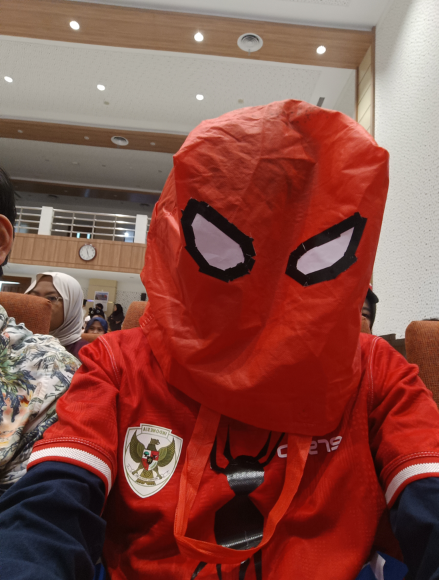

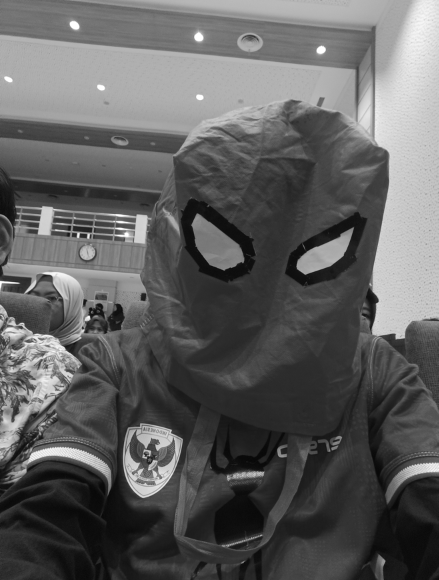

In [75]:
image = cv2.imread("/content/Tugas-Pengenalan-Pola-Feature-Extraction/Screenshot 2026-11-15 001519.png")
cv2_imshow(image)

image_dark = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) #pada penugasan ini akan menggunakan grayscale untuk kesederhanaan
cv2_imshow(image_dark)

## B) Basic LBP

Kode ini akan mengimplementasikan metode LBP default dimana padding akan diberikan kepada citra lalu pada tiap piksel, akan dibandingkan dengan 8 piksel yang mengelilinginya, jika nilai piksel neighbor >= piksel tengah maka kode akan append 1, jika nilai piksel neighbor < piksel tengah maka kode akan append 0. Nilai pada array tersebut kemudian akan dikalikan dengan 2^index dan dijumlahkan untuk memperoleh piksel barunya dalam bentuk desimal.

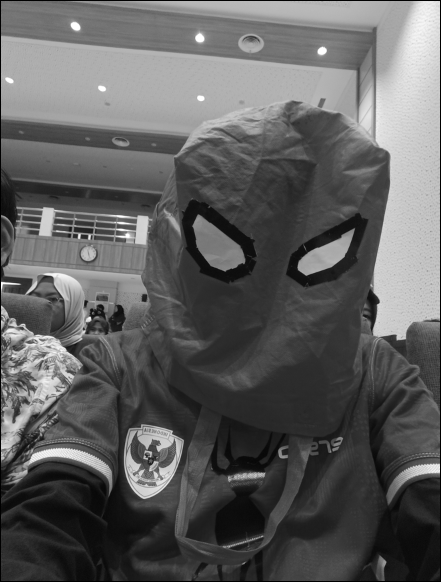

In [76]:
#0 padding
height, width = image_dark.shape

def zero_padding(img, h, w):
  z = np.zeros((h+2, w+2), dtype=np.uint8)
  z[1:h+1, 1:w+1] = img
  return z

image_dark_padded = zero_padding(image_dark, height, width)
cv2_imshow(image_dark_padded)

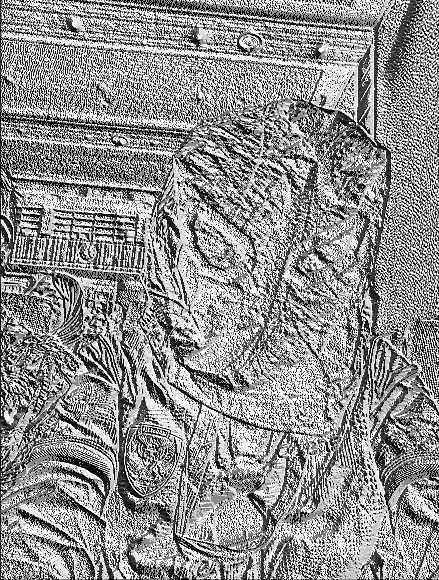

In [ ]:
def basic_lbp(img): #operasi lbp sederhana (arah clockwise)
  height, width = img.shape #buat image kosong, hasil LBP akan ditaro disini
  lbp_img = np.zeros((height-2, width-2), dtype=np.uint8)

  for i in range(1, height-1):
    for j in range(1, width-1):
      bin = []
      center = img[i, j] #asumsi center adalah (1,1) pada koordinat (x, y)

      #perbandingan center dengan (0,0), (1,0), (2,0)
      for k in range(1, 4):
        if img[i-1, j-2+k] >= center:
          bin.append(1)
        else:
          bin.append(0)

      #perbandingan center dengan (2, 1)
      if img[i, j+1] >= center:
        bin.append(1)
      else:
        bin.append(0)

      #perbandingan center dengan (2,2), (1,2), (0,2)
      for k in range(3):
        if img[i+1, j+1-k] >= center:
          bin.append(1)
        else:
          bin.append(0)

      #perbandingan center dengan (0, 1)
      if img[i, j-1] >= center:
        bin.append(1)
      else:
        bin.append(0)

      p_baru = 0
      for binary in range(8):
        p_baru = p_baru + 2**binary * bin[binary]
      lbp_img[i-1, j-1] = p_baru

  return lbp_img

basic_lbp_image = basic_lbp(image_dark_padded)
cv2_imshow(basic_lbp_image)

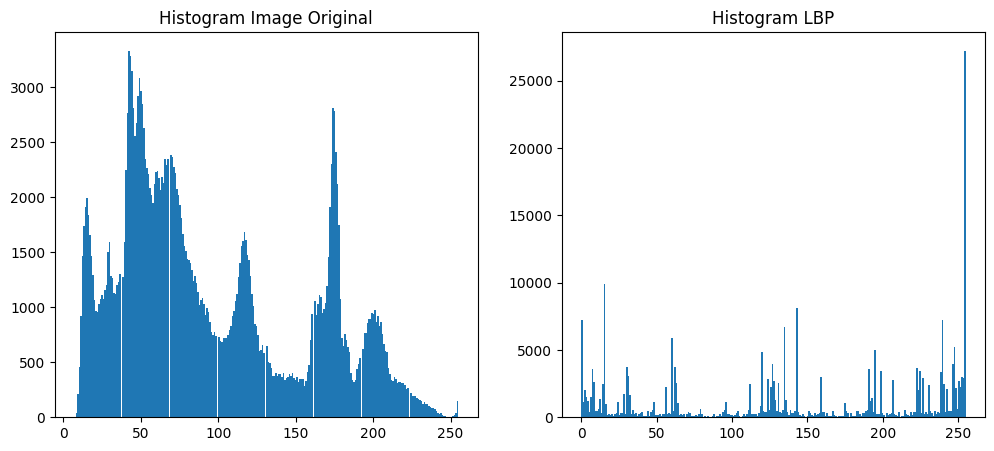

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].hist(image_dark.ravel(), bins=256)
ax[0].set_title("Histogram Image Original")

ax[1].hist(basic_lbp_image.ravel(), bins=256)
ax[1].set_title("Histogram LBP")

plt.show()

## C) Bilinear Interpolation LBP

Basic LBP dapat menangkap detil kecil dan *microtexture* pada citra dengan secara langsung membandingkan piksel tengah dengan piksel neighbornya. LBP menggunakan *bilinear interpolation* dapat memperluas perbandingan piksel dengan meningkatkan nilai radius lingkaran untuk menangkap detil-detil *macrotexture* dan menjadi metode rotation invariant untuk LBP. Implementasi disini bereksperimen dengan beberapa nilai titik lingkaran dan nilai radius untuk mencari parameter yang optimal.

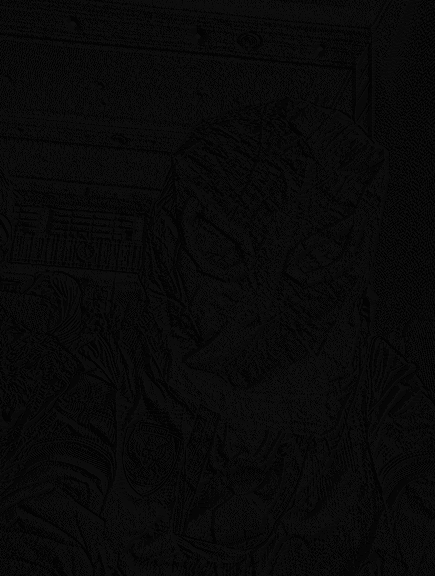

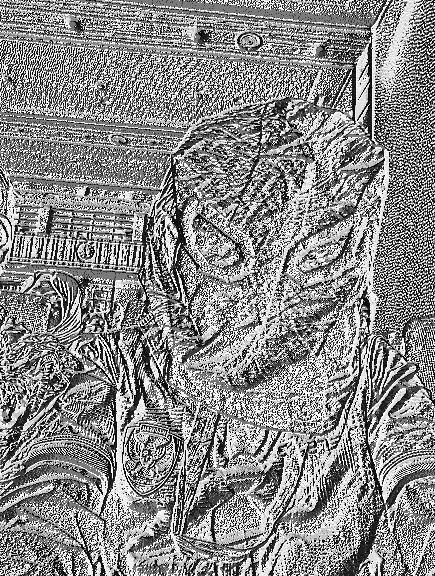

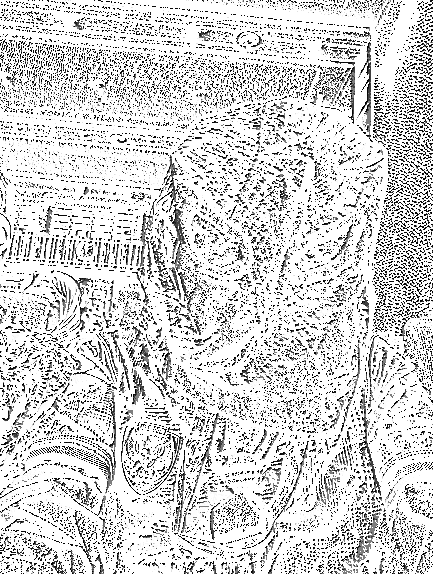

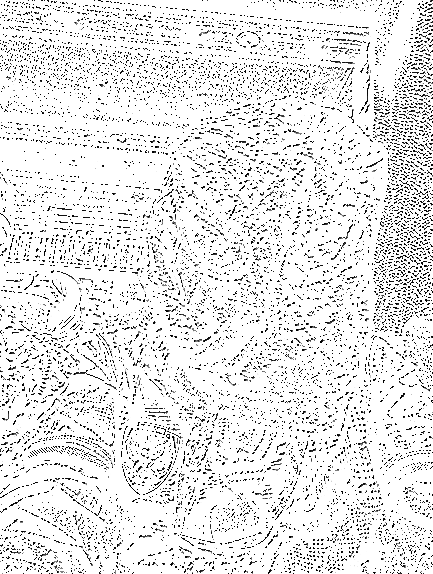

In [ ]:
import math

def bilinear_lbp(img, points, radius):
  if points <= 8: #data type perlu dinamis
        d = np.uint8
  elif points <= 16:
        d = np.uint16
  else:
        d = np.uint32

  margin = math.ceil(radius) + 1
  lbp_img = np.zeros(
        (height - 2*margin, width - 2*margin),
        dtype=d
    )

  for i in range(margin, height-margin):
    for j in range(margin, width-margin):
      bin = []
      center = img[i, j]

      #menggunakan rumus dari ppt materi pertemuan 11 halaman 14-15
      for p in range(points):
        x = j - radius * math.sin((2 * math.pi * p) / points)
        y = i + radius * math.cos((2 * math.pi * p) / points)

        x1 = math.floor(x)
        y1 = math.floor(y)
        x2 = x1 + 1
        y2 = y1 + 1
        suku1 = (x2 - x)*(y2 - y)*img[y1, x1] / ((x2 - x1)*(y2 - y1))
        suku2 = (x - x1)*(y2 - y)*img[y1, x2] / ((x2 - x1)*(y2 - y1))
        suku3 = (x2 - x)*(y - y1)*img[y2, x1] / ((x2 - x1)*(y2 - y1))
        suku4 = (x - x1)*(y - y1)*img[y2, x2] / ((x2 - x1)*(y2 - y1))

        val = suku1 + suku2 + suku3 + suku4
        bin.append(val)

      #ubah nilai terinterpolasi menjadi biner
      for p in range(points):
        if bin[p] >= center:
          bin[p] = 1
        else:
          bin[p] = 0

      lbp_value = 0
      for p in range(points):
        lbp_value = lbp_value + 2**p * bin[p]

      lbp_img[i-margin, j-margin] = lbp_value

  return lbp_img

results = []
bilinear_lbp_image = bilinear_lbp(image_dark_padded, 4, 1)
results.append(bilinear_lbp_image)
cv2_imshow(bilinear_lbp_image)

bilinear_lbp_image = bilinear_lbp(image_dark_padded, 8, 1)
results.append(bilinear_lbp_image)
cv2_imshow(bilinear_lbp_image)

bilinear_lbp_image = bilinear_lbp(image_dark_padded, 12, 1.5)
results.append(bilinear_lbp_image)
cv2_imshow(bilinear_lbp_image)

bilinear_lbp_image = bilinear_lbp(image_dark_padded, 16, 2)
results.append(bilinear_lbp_image)
cv2_imshow(bilinear_lbp_image)

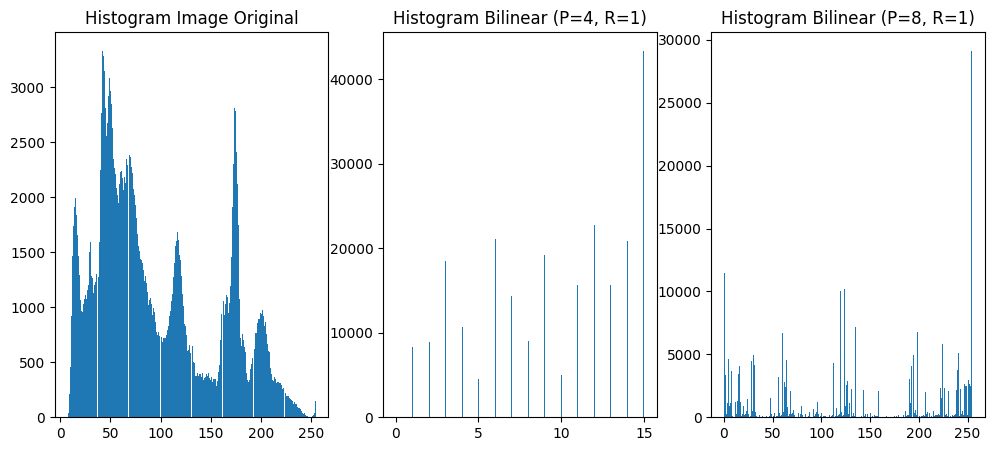

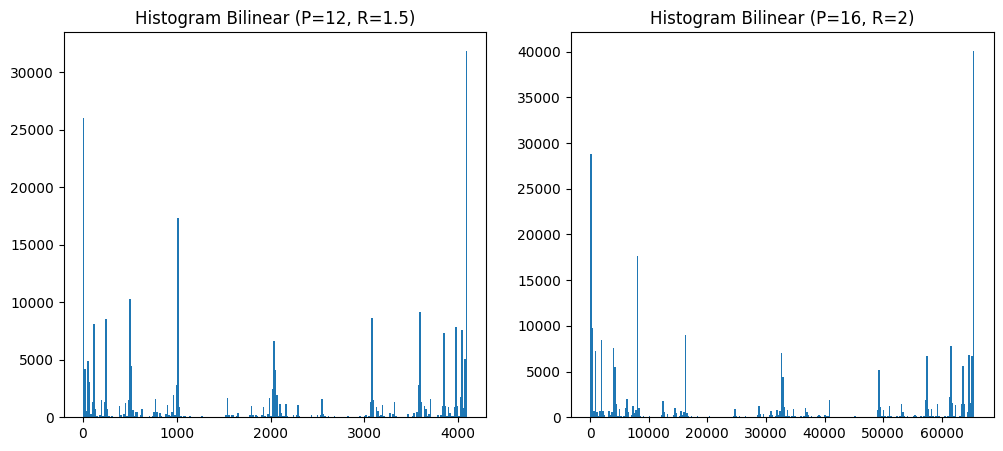

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 5))
ax[0].hist(image_dark.ravel(), bins=256)
ax[0].set_title("Histogram Image Original")

ax[1].hist(results[0].ravel(), bins=256)
ax[1].set_title("Histogram Bilinear (P=4, R=1)")

ax[2].hist(results[1].ravel(), bins=256)
ax[2].set_title("Histogram Bilinear (P=8, R=1)")

plt.show()


fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].hist(results[2].ravel(), bins=256)
ax[0].set_title("Histogram Bilinear (P=12, R=1.5)")

ax[1].hist(results[3].ravel(), bins=256)
ax[1].set_title("Histogram Bilinear (P=16, R=2)")

plt.show()

## D) Rotation Invariant LBP

Salah satu masalah pada LBP adalah jika citra dirotasi maka nilai bits yang diperoleh bisa berbeda, misalnya kita memperoleh LBP suatu citra 01001001 yaitu 146 dalam decimal, jika dirotasi maka orientasi piksel yang mengelilingi piksel tengah berbeda sehingga LBP dapar berubah menjadi 10100100 yaitu 37 dalam decimal. Salah satu solusi untuk masalah ini adalah untuk menghitung semua kombinasi rotasi dari LBP suatu piksel, lalu mengambil nilai minimumnya saja.

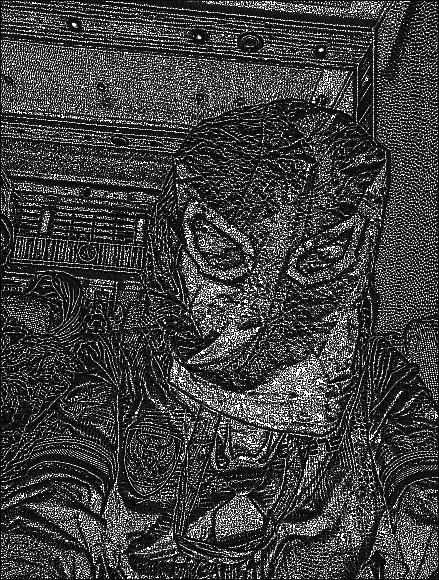

In [ ]:
def ri_lbp(img): #operasi lbp sederhana (arah clockwise)
  min_values = []
  height, width = img.shape #buat image kosong, hasil LBP akan ditaro disini
  lbp_img = np.zeros((height-2, width-2), dtype=np.uint8)

  for i in range(1, height-1):
    for j in range(1, width-1):
      bin = []
      center = img[i, j] #asumsi center adalah (1,1) pada koordinat (x, y)

      #perbandingan center dengan (0,0), (1,0), (2,0)
      for k in range(1, 4):
        if img[i-1, j-2+k] >= center:
          bin.append(1)
        else:
          bin.append(0)

      #perbandingan center dengan (2, 1)
      if img[i, j+1] >= center:
        bin.append(1)
      else:
        bin.append(0)

      #perbandingan center dengan (2,2), (1,2), (0,2)
      for k in range(3):
        if img[i+1, j+1-k] >= center:
          bin.append(1)
        else:
          bin.append(0)

      #perbandingan center dengan (0, 1)
      if img[i, j-1] >= center:
        bin.append(1)
      else:
        bin.append(0)

      values = []

      for b in range(8):
        candidate_pixel = 0
        for binary in range(8): #hitung hasil biner
          candidate_pixel = candidate_pixel + 2**binary * bin[binary]

        values.append(candidate_pixel) #masukkan nilai ke array
        bin = np.roll(bin, -1) #rotasi biner

      mi = min(values)
      lbp_img[i-1, j-1] = mi
      min_values.append(mi)

  return lbp_img, min_values

ri_lbp_image, min_values = ri_lbp(image_dark_padded)
cv2_imshow(ri_lbp_image)

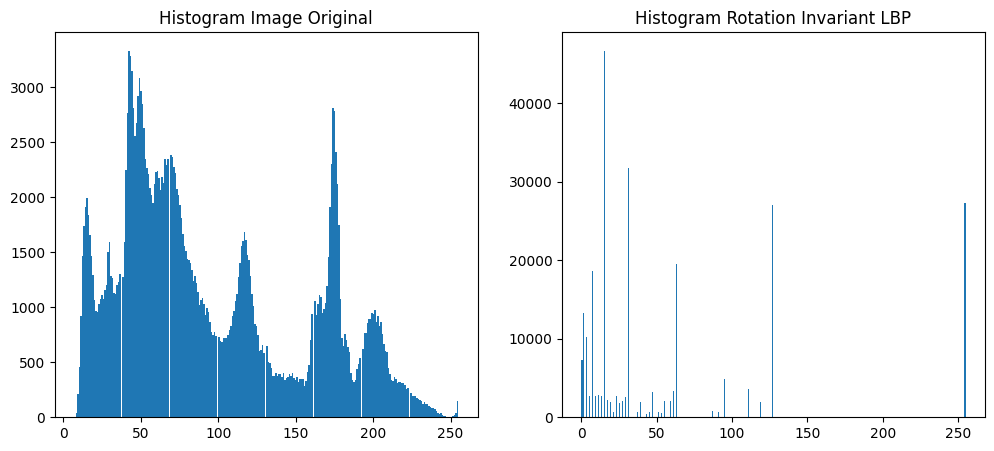

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].hist(image_dark.ravel(), bins=256)
ax[0].set_title("Histogram Image Original")

ax[1].hist(ri_lbp_image.ravel(), bins=256)
ax[1].set_title("Histogram Rotation Invariant LBP")

plt.show()

## E) Uniform LBP

Pola uniform pada suatu citra dapat berupa flat area, spots, edges, atau lainnya, suatu platform dikatakan uniform jika LBPnya memiliki kurang dari atau sama dengan 2 transisi (U <= 2). Misalnya suatu hasil bits 10000001 memiliki U=2. Pada penugasan ini, suatu piksel yang dianggap tidak uniform akan diubah menjadi piksel putih saja.

ada berapa pixel not uniform:  52869


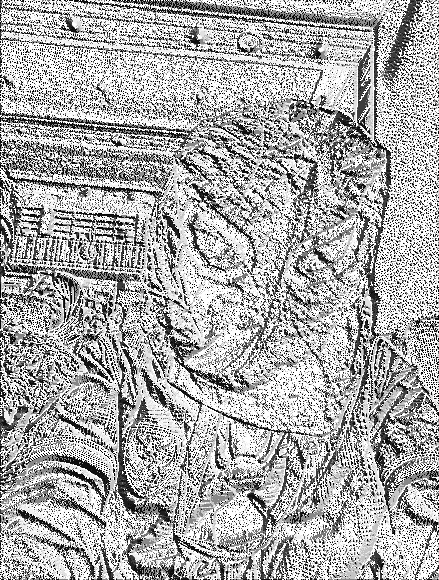

In [ ]:
def get_U(binary):
  n = len(binary)
  u = 0
  for i in range(n):
    if i < n-1:
      if binary[i] != binary[i+1]:
        u = u +1
  if binary[n-1] != binary[0]:
    u = u+1

  return u

def uniform_lbp(img): #operasi lbp sederhana (arah clockwise)
  not_uniform = 0
  height, width = img.shape #buat image kosong, hasil LBP akan ditaro disini
  lbp_img = np.zeros((height-2, width-2), dtype=np.uint8)

  for i in range(1, height-1):
    for j in range(1, width-1):
      bin = []
      center = img[i, j] #asumsi center adalah (1,1) pada koordinat (x, y)

      #perbandingan center dengan (0,0), (1,0), (2,0)
      for k in range(1, 4):
        if img[i-1, j-2+k] >= center:
          bin.append(1)
        else:
          bin.append(0)

      #perbandingan center dengan (2, 1)
      if img[i, j+1] >= center:
        bin.append(1)
      else:
        bin.append(0)

      #perbandingan center dengan (2,2), (1,2), (0,2)
      for k in range(3):
        if img[i+1, j+1-k] >= center:
          bin.append(1)
        else:
          bin.append(0)

      #perbandingan center dengan (0, 1)
      if img[i, j-1] >= center:
        bin.append(1)
      else:
        bin.append(0)

      transitions = get_U(bin) #hitung hasil biner jika uniform, pixel = putih jika tidak uniform
      if transitions <= 2:
        pixel = 0
        for binary in range(8):
          pixel = pixel + 2**binary * bin[binary]
      else:
        pixel = 255
        not_uniform = not_uniform + 1

      lbp_img[i-1, j-1] = pixel

  return lbp_img, not_uniform

uniform_lbp_image, not_uniform = uniform_lbp(image_dark_padded)
print("ada berapa pixel not uniform: ", not_uniform)
cv2_imshow(uniform_lbp_image)

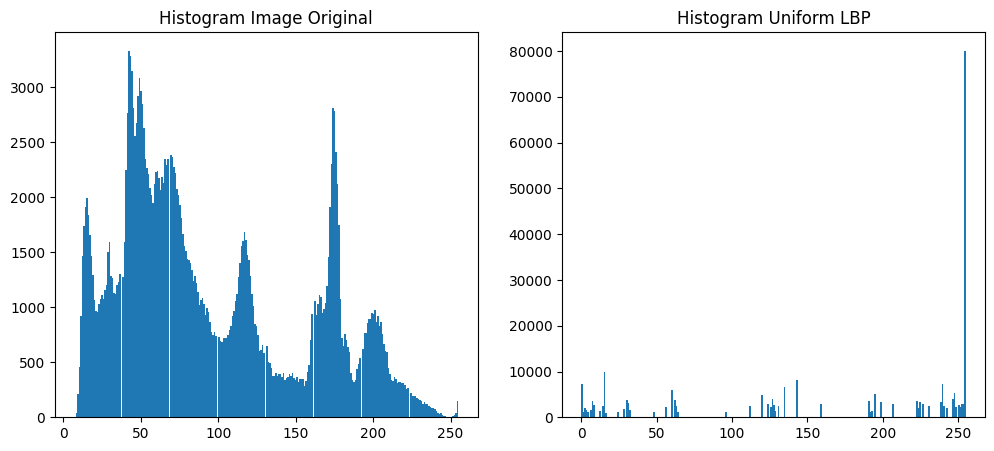

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].hist(image_dark.ravel(), bins=256)
ax[0].set_title("Histogram Image Original")

ax[1].hist(uniform_lbp_image.ravel(), bins=256)
ax[1].set_title("Histogram Uniform LBP")

plt.show()

## F) LBP Menggunakan Library

Berikut adalah implementasi LBP dalam kode menggunakan library, metode yang tersedia adalah default, rotation invariant, dan uniform. Hasilnya akan dibandingkan dengan implementasi kode yang telah dilakukan dengan manual.

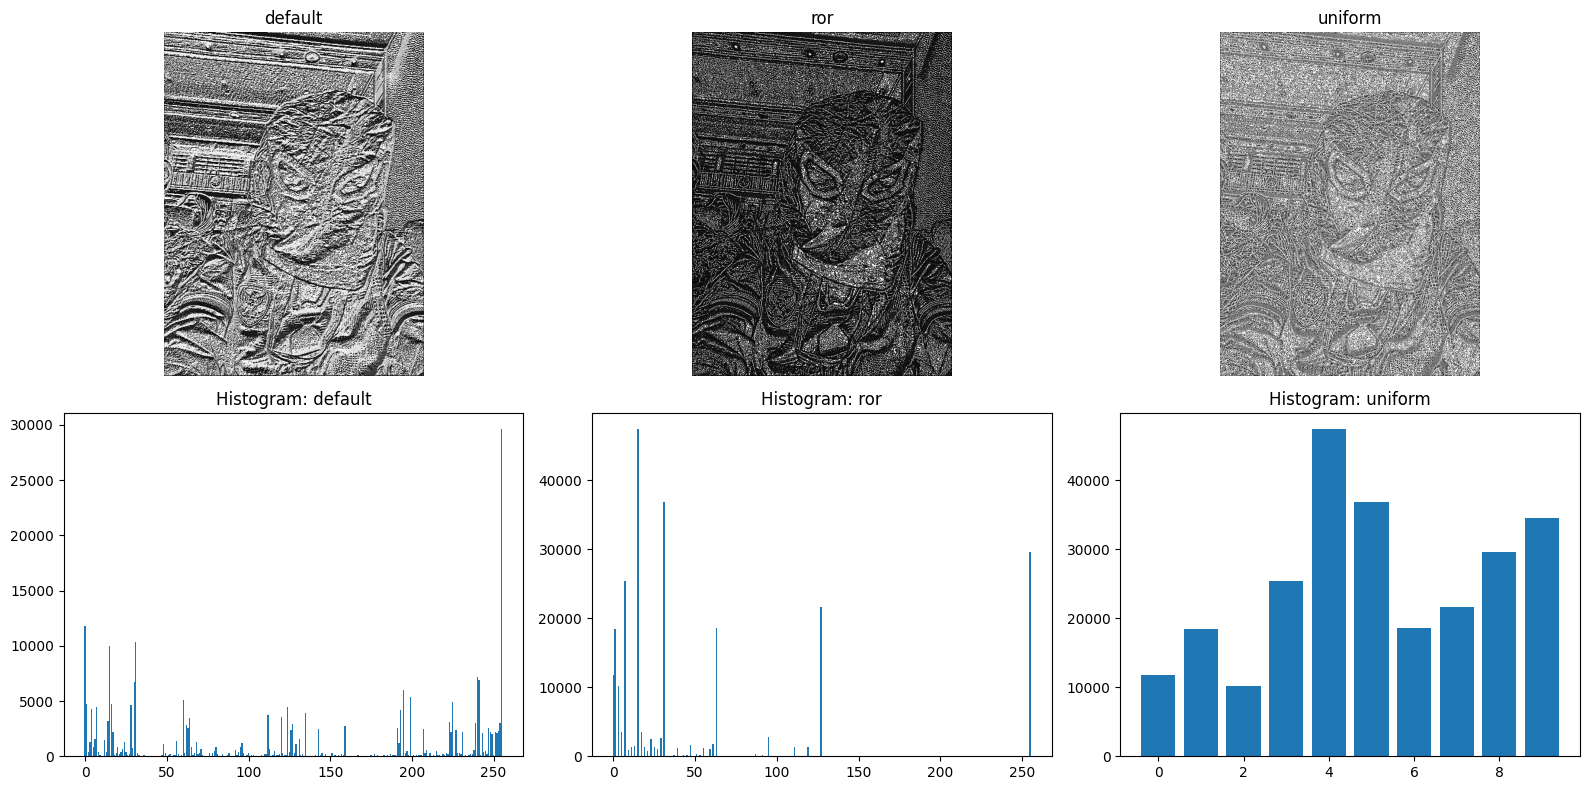

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

P = 8
R = 1
methods = ['default', 'ror', 'uniform']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for idx, method in enumerate(methods):
    lbp = local_binary_pattern( #buat image menggunakan method yang terpilih
        image_dark,
        P,
        R,
        method=method
    )

    #display hasil gambar dan histogram
    axes[0, idx].imshow(lbp, cmap='gray')
    axes[0, idx].set_title(f'{method}')
    axes[0, idx].axis('off')

    if method == 'default':
        bins = 2**P
    elif method == 'ror':
        bins = 2**P
    elif method == 'uniform':
        bins = P + 2

    hist = np.bincount(lbp.astype(int).ravel())

    axes[1, idx].bar(range(bins), hist)
    axes[1, idx].set_title(f'Histogram: {method}')

plt.tight_layout()
plt.show()